# 06 · Optimización con Optuna y política de triaje de 3 estados — AccessGuard AI

Con la política de 2 estados (aprobar / denegar) el modelo apenas mejoraba a las políticas triviales, y **"mandar todo a revisión" resultó más barato que cualquier modelo de 2 estados**.
La salida es una política de **3 estados con dos umbrales**:

| Estado | Regla (sobre p = probabilidad de *aprobar*) | Costo |
|---|---|---|
| **Aprobar** automáticamente | p ≥ `T_high` | `COST_FP` si era un acceso a denegar (falso positivo); 0 si era legítimo |
| **Revisar** manualmente | `T_low` ≤ p < `T_high` | `COST_REVIEW` por cada caso enviado a la mesa de ayuda (se asume que el analista acierta) |
| **Denegar** automáticamente | p < `T_low` | `COST_FN` si era un usuario legítimo (falso negativo); 0 si era correcto |

**Qué se optimiza:** Optuna busca **a la vez** los hiperparámetros del modelo y la pareja de umbrales (`T_low` ∈ [0,01; 0,50], `T_high` ∈ [0,51; 0,99]) para **minimizar el costo operativo total por solicitud**
en validación cruzada por gerente (5 pliegues). Los costos salen de `config/settings.py` (son **supuestos de trabajo**, no datos medidos).

**Reserva (holdout):** se evalúa **una sola vez** al final (sección 8); no se usa para decidir nada antes.

In [1]:
import sys, warnings, json, time, os
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, optuna
from sklearn.metrics import roc_auc_score
from config.settings import PROCESSED_DIR, REPORTS_DIR, ROOT as PROJECT_ROOT, SEED, TARGET, GROUP_COL, COST_FP, COST_FN, COST_REVIEW
MODELS_DIR = PROJECT_ROOT / "models"
for d in (PROCESSED_DIR, REPORTS_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)               # se crean si no existen
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 1. Finalista, costos y datos

In [2]:
from accessguard.modeling import (baseline_costs, best_threshold, build_model, build_pipeline, expected_cost, fold_matrices,
                                  make_cv, metrics_at, predict_triage, suggest_params, triage_cost, triage_grid, triage_summary)

finalists = json.loads((REPORTS_DIR / "05_finalistas.json").read_text(encoding="utf-8"))
MODEL = finalists["mejor"]
print("Finalistas del torneo:", finalists["finalistas"], "→ se optimiza:", MODEL)
print(f"Costos (USD): COST_FP = {COST_FP:,.0f} · COST_FN = {COST_FN:,.0f} · COST_REVIEW = {COST_REVIEW:,.0f}")

train = pd.read_csv(PROCESSED_DIR / "train_clean.csv")
y = train[TARGET].to_numpy(); X = train.drop(columns=TARGET)
folds = fold_matrices(X, y, X[GROUP_COL], make_cv(5, SEED), seed=SEED)
base = baseline_costs(y, COST_FP, COST_FN, COST_REVIEW)
print(f"{len(X):,} filas · {X[GROUP_COL].nunique():,} gerentes · {folds[0][0].shape[1]} variables · 5 pliegues por gerente")
print("Costo por solicitud de las políticas triviales:", {k: round(v, 2) for k, v in base.items()})

Finalistas del torneo: ['Random Forest', 'LogReg ElasticNet'] → se optimiza: Random Forest
Costos (USD): COST_FP = 500 · COST_FN = 30 · COST_REVIEW = 6


26,215 filas · 3,360 gerentes · 29 variables · 5 pliegues por gerente
Costo por solicitud de las políticas triviales: {'aprobar todo': 28.95, 'denegar todo': 28.26, 'revisar todo': 6.0}


**Un dato clave del problema.** "Revisar todo" cuesta exactamente `COST_REVIEW` = 6 USD por solicitud. Para que una decisión automática valga la pena debe costar menos que eso:

* aprobar solo conviene si la probabilidad de que sea un acceso indebido es menor que `COST_REVIEW / COST_FP` = 1,2 % → **p(aprobar) ≳ 0,988**;
* denegar solo conviene si p(legítimo) · `COST_FN` < `COST_REVIEW` → **p(aprobar) ≲ 0,20**.

Por eso `T_high` tiene que estar muy cerca de 0,99 y `T_low` cerca de 0,2: el modelo solo aporta en los extremos de confianza, y el resto va a revisión. Cuánto valor hay depende de **cuántos casos** caen en esos extremos.

In [3]:
N_TRIALS = 50

def objective(trial):
    params = suggest_params(trial, MODEL)
    t_low = trial.suggest_float("t_low", 0.01, 0.50)
    t_high = trial.suggest_float("t_high", 0.51, 0.99)
    p_oof = np.zeros(len(y))
    for X_tr, y_tr, X_va, y_va, idx_va in folds:
        p_oof[idx_va] = build_model(MODEL, params, seed=SEED).fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
    trial.set_user_attr("roc_auc", float(roc_auc_score(y, p_oof)))
    return triage_cost(y, p_oof, t_low, t_high, COST_FP, COST_FN, COST_REVIEW)   # costo por solicitud: se MINIMIZA

## 2. Estudio de Optuna (hiperparámetros + umbrales)

Muestreador bayesiano (TPE) con semilla fija. La función objetivo es el **costo operativo total por solicitud** de la política de 3 estados, calculado sobre las predicciones fuera de pliegue (cada fila predicha por un modelo que no la vio, gerentes nunca vistos).
El espacio de búsqueda de los hiperparámetros está acotado por conocimiento del algoritmo (`suggest_params`).

In [4]:
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name=f"iam-3estados-{MODEL}")
t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS)
best = study.best_params
T_LOW, T_HIGH = best["t_low"], best["t_high"]
HP = {k: v for k, v in best.items() if k not in ("t_low", "t_high")}
print(f"{N_TRIALS} ensayos en {time.time() - t0:.0f} s · mejor costo (CV) = {study.best_value:.3f} USD/solicitud (ensayo {study.best_trial.number})")
print(f"T_low = {T_LOW:.3f} · T_high = {T_HIGH:.3f}")
print("hiperparámetros:", HP)

50 ensayos en 655 s · mejor costo (CV) = 6.008 USD/solicitud (ensayo 32)
T_low = 0.148 · T_high = 0.983
hiperparámetros: {'n_estimators': 200, 'max_depth': 29, 'min_samples_leaf': 20, 'max_features': 0.6923479746025818}


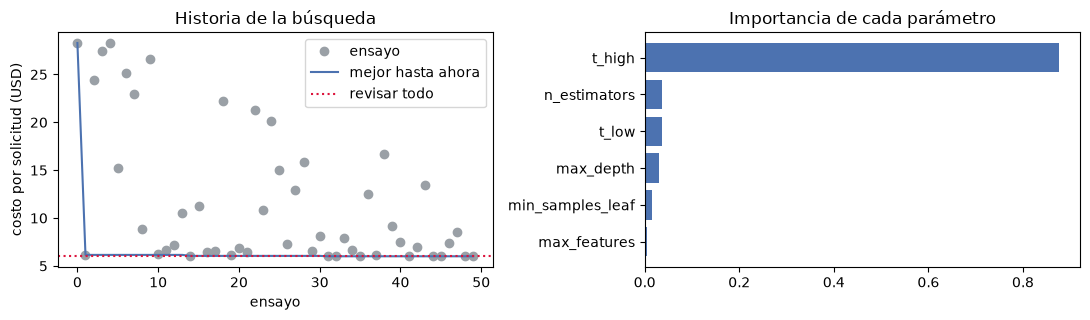

,number,value,user_attrs_roc_auc,params_max_depth,params_max_features,params_min_samples_leaf,params_n_estimators,params_t_high,params_t_low
32,32,6.0084,0.7027,29,0.6923,20,200,0.9826,0.1483
35,35,6.0095,0.7024,28,0.8684,19,200,0.9826,0.0504
31,31,6.0114,0.7090,25,0.6891,26,200,0.9900,0.0822
44,44,6.0131,0.7066,27,0.6187,24,200,0.9862,0.1067
45,45,6.0290,0.7024,25,0.8794,19,200,0.9865,0.0670


In [5]:
vals = np.array([t.value for t in study.trials])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(vals, "o", color="#9aa0a6", label="ensayo"); axes[0].plot(np.minimum.accumulate(vals), "-", color="#4c72b0", label="mejor hasta ahora")
axes[0].axhline(COST_REVIEW, color="crimson", ls=":", label="revisar todo")
axes[0].set_xlabel("ensayo"); axes[0].set_ylabel("costo por solicitud (USD)"); axes[0].legend(); axes[0].set_title("Historia de la búsqueda")
imp = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
axes[1].barh(imp.index, imp.values, color="#4c72b0"); axes[1].set_title("Importancia de cada parámetro")
plt.tight_layout(); plt.show()
tdf = study.trials_dataframe()
tdf.sort_values("value").head(5)[["number", "value", "user_attrs_roc_auc"] + [c for c in tdf.columns if c.startswith("params_")]].round(4)

## 3. Predicciones fuera de pliegue del modelo optimizado y desglose de la política

Se recalculan las probabilidades OOF con los mejores hiperparámetros y se aplica la política `(T_low, T_high)`.

In [6]:
p_oof = np.zeros(len(y))
for X_tr, y_tr, X_va, y_va, idx_va in folds:
    p_oof[idx_va] = build_model(MODEL, HP, seed=SEED).fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
m = metrics_at(y, p_oof)
print(f"OOF · ROC-AUC = {m['roc_auc']:.4f} · PR-AUC denegar = {m['pr_auc_deny']:.4f} (azar = {1 - y.mean():.4f})")
s = triage_summary(y, p_oof, T_LOW, T_HIGH, COST_FP, COST_FN, COST_REVIEW)
assert np.isclose(s["cost"], study.best_value)
pd.DataFrame({
    "estado": ["Aprobar (p ≥ T_high)", "Revisar", "Denegar (p < T_low)"],
    "% de solicitudes": [s["pct_approve"], s["pct_review"], s["pct_deny"]],
    "errores que cuestan": [f"{s['fp_auto_approve']} accesos indebidos aprobados (FP)", f"{s['n_review']} casos a la mesa de ayuda", f"{s['fn_auto_deny']} legítimos denegados (FN)"],
    "costo por solicitud (USD)": [COST_FP * s["fp_auto_approve"] / s["n"], COST_REVIEW * s["n_review"] / s["n"], COST_FN * s["fn_auto_deny"] / s["n"]],
}).set_index("estado").round(3)

OOF · ROC-AUC = 0.7027 · PR-AUC denegar = 0.1603 (azar = 0.0579)


,% de solicitudes,errores que cuestan,costo por solicitud (USD)
estado,,,
Aprobar (p ≥ T_high),0.034,11 accesos indebidos aprobados (FP),0.210
Revisar,0.966,25335 casos a la mesa de ayuda,5.799
Denegar (p < T_low),0.000,0 legítimos denegados (FN),0.000


### Mapa de costo según los umbrales

Costo por solicitud para todas las parejas `(T_low, T_high)` con las probabilidades OOF del modelo optimizado (la estrella es la pareja elegida por Optuna). Una región plana y amplia significa que la política es robusta a pequeños cambios de umbral.

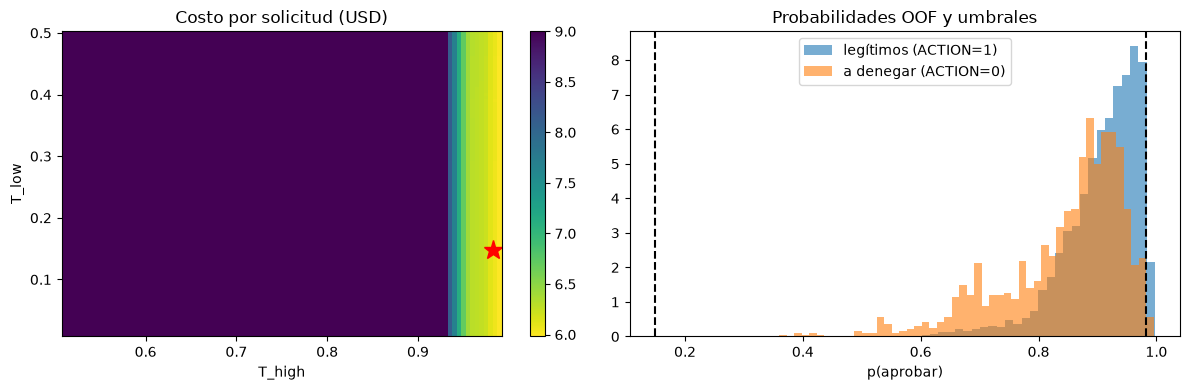

Mínimo de la rejilla: 5.981 USD · pareja de Optuna: 6.008 USD


In [7]:
lows = np.linspace(0.01, 0.50, 99); highs = np.linspace(0.51, 0.99, 97)
grid = triage_grid(y, p_oof, COST_FP, COST_FN, COST_REVIEW, lows, highs)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
im = axes[0].pcolormesh(highs, lows, np.clip(grid, None, COST_REVIEW * 1.5), shading="auto", cmap="viridis_r")
axes[0].plot(T_HIGH, T_LOW, "*", color="red", ms=14); axes[0].set_xlabel("T_high"); axes[0].set_ylabel("T_low"); axes[0].set_title("Costo por solicitud (USD)")
plt.colorbar(im, ax=axes[0])
axes[1].hist(p_oof[y == 1], bins=50, alpha=0.6, label="legítimos (ACTION=1)", density=True)
axes[1].hist(p_oof[y == 0], bins=50, alpha=0.6, label="a denegar (ACTION=0)", density=True)
axes[1].axvline(T_LOW, color="k", ls="--"); axes[1].axvline(T_HIGH, color="k", ls="--"); axes[1].set_xlabel("p(aprobar)"); axes[1].set_title("Probabilidades OOF y umbrales"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Mínimo de la rejilla: {np.nanmin(grid):.3f} USD · pareja de Optuna: {study.best_value:.3f} USD")

## 4. Comparación con las políticas de referencia (validación cruzada)

Se compara contra: aprobar todo, denegar todo, **revisar todo**, y la política de **2 estados** con su mejor umbral. También contra el mismo Random Forest **sin ajustar hiperparámetros** (parámetros por defecto) con sus umbrales óptimos por rejilla, para saber cuánto aporta Optuna más allá de simplemente poner bien los umbrales.

In [8]:
p_def = np.zeros(len(y))
for X_tr, y_tr, X_va, y_va, idx_va in folds:
    p_def[idx_va] = build_model(MODEL, None, seed=SEED).fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
g_def = triage_grid(y, p_def, COST_FP, COST_FN, COST_REVIEW, lows, highs)
i, j = np.unravel_index(np.nanargmin(g_def), g_def.shape)
t2, c2, _ = best_threshold(y, p_oof, COST_FP, COST_FN)

cv_table = pd.DataFrame({"costo por solicitud (USD)": {
    "aprobar todo": base["aprobar todo"], "denegar todo": base["denegar todo"], "revisar todo": base["revisar todo"],
    f"modelo, 2 estados (umbral {t2:.3f})": c2,
    f"modelo por defecto, 3 estados (umbrales {lows[i]:.2f}/{highs[j]:.2f})": g_def[i, j],
    f"modelo optimizado, 3 estados ({T_LOW:.3f}/{T_HIGH:.3f})": study.best_value,
}})
best_trivial = min(base.values())
cv_table["ahorro vs mejor trivial (USD)"] = best_trivial - cv_table["costo por solicitud (USD)"]
cv_table["ahorro vs mejor trivial (%)"] = 100 * cv_table["ahorro vs mejor trivial (USD)"] / best_trivial
cv_table.round(3)

,costo por solicitud (USD),ahorro vs mejor trivial (USD),ahorro vs mejor trivial (%)
aprobar todo,28.953,-22.953,-382.548
denegar todo,28.263,-22.263,-371.047
revisar todo,6.000,0.000,0.000
"modelo, 2 estados (umbral 0.895)",20.629,-14.629,-243.824
"modelo por defecto, 3 estados (umbrales 0.35/0.98)",5.916,0.084,1.401
"modelo optimizado, 3 estados (0.148/0.983)",6.008,-0.008,-0.140


**Cómo leerlo.** El ahorro se mide contra la **mejor política trivial** (la más barata de las tres; hoy es "revisar todo"). Un ahorro positivo significa que el modelo, al decidir solo los casos seguros, cuesta menos que revisar todo.
El umbral y los hiperparámetros se eligieron con estos mismos datos, así que **el ahorro de validación cruzada es optimista**: la cifra honesta es la de la reserva (sección 8). Antes, un intervalo por gerentes:

In [9]:
rng = np.random.default_rng(SEED)
mgr = X[GROUP_COL].to_numpy(); uniq = np.unique(mgr)
idx_by = pd.Series(np.arange(len(mgr))).groupby(mgr).apply(np.array)
sav = []
for _ in range(500):
    ii = np.concatenate([idx_by.loc[g] for g in rng.choice(uniq, len(uniq), replace=True)])
    sav.append(COST_REVIEW - triage_cost(y[ii], p_oof[ii], T_LOW, T_HIGH, COST_FP, COST_FN, COST_REVIEW))
lo, hi = np.percentile(sav, [2.5, 97.5])
print(f"Ahorro por solicitud vs 'revisar todo' (validación cruzada): {np.mean(sav):.3f} USD · IC 95 % por gerentes [{lo:.3f}, {hi:.3f}]")
print("Lectura:", "el intervalo queda por encima de 0" if lo > 0 else "el intervalo incluye 0 (o es negativo): en validación cruzada no se distingue de revisar todo")

Ahorro por solicitud vs 'revisar todo' (validación cruzada): -0.009 USD · IC 95 % por gerentes [-0.140, 0.109]
Lectura: el intervalo incluye 0 (o es negativo): en validación cruzada no se distingue de revisar todo


## 5. Sensibilidad a los costos supuestos

Como los costos no son medidos, se recalculan los mejores umbrales (por rejilla, sobre las mismas probabilidades OOF) para distintos valores de `COST_FP` y `COST_REVIEW`. Muestra **cuándo el modelo deja de valer la pena**.

In [10]:
rows = []
for c_fp in [100, 250, 500, 1000, 2000]:
    for c_rev in [3, 6, 12]:
        g = triage_grid(y, p_oof, c_fp, COST_FN, c_rev, lows, highs)
        i, j = np.unravel_index(np.nanargmin(g), g.shape)
        b = baseline_costs(y, c_fp, COST_FN, c_rev)
        s2 = triage_summary(y, p_oof, lows[i], highs[j], c_fp, COST_FN, c_rev)
        rows.append({"COST_FP": c_fp, "COST_REVIEW": c_rev, "T_low": lows[i], "T_high": highs[j], "costo modelo": g[i, j],
                     "mejor trivial": min(b.values()), "ahorro": min(b.values()) - g[i, j],
                     "% revisar": 100 * s2["pct_review"], "% aprobar auto": 100 * s2["pct_approve"], "% denegar auto": 100 * s2["pct_deny"]})
sens = pd.DataFrame(rows)
sens.to_csv(REPORTS_DIR / "06_sensibilidad_costos.csv", index=False)
sens.round(3)

,COST_FP,COST_REVIEW,T_low,T_high,costo modelo,mejor trivial,ahorro,% revisar,% aprobar auto,% denegar auto
0,100,3,0.01,0.950,2.616,3.000,0.384,70.807,29.193,0.000
1,100,6,0.01,0.890,4.337,5.791,1.453,32.363,67.637,0.000
2,100,12,0.40,0.800,5.117,5.791,0.674,6.924,93.054,0.023
3,250,3,0.01,0.990,2.990,3.000,0.010,99.363,0.637,0.000
4,250,6,0.01,0.955,5.444,6.000,0.556,74.846,25.154,0.000
5,250,12,0.40,0.935,9.501,12.000,2.499,60.404,39.573,0.023
6,500,3,0.01,0.990,3.000,3.000,0.000,99.363,0.637,0.000
7,500,6,0.01,0.990,5.981,6.000,0.019,99.363,0.637,0.000
8,500,12,0.40,0.955,10.888,12.000,1.112,74.824,25.154,0.023
9,1000,3,0.01,0.990,3.019,3.000,-0.019,99.363,0.637,0.000


## 6. Modelo final y exportación

Se entrena el pipeline completo (`IAMFeatureBuilder` + modelo con los mejores hiperparámetros) con **todo** el entrenamiento y se guarda un paquete con el pipeline, los dos umbrales y los metadatos en
**`models/model.joblib`** (el nombre que espera la app) y una copia en **`models/best_model_iam.joblib`**.
Para cargarlo hace falta `src/` en el `PYTHONPATH` (el pipeline usa `accessguard.engineering`). Uso: `predict_triage(bundle, X)` (en `accessguard.modeling`).

> La app de Streamlit actual (`app/streamlit_app.py`) es la plantilla del curso (otro caso, módulo `creditsight`): sigue necesitando adaptarse para leer este paquete y su esquema de entrada.

In [11]:
final_pipe = build_pipeline(MODEL, HP, seed=SEED).fit(X, y)

bundle = {
    "pipeline": final_pipe,
    "t_low": float(T_LOW), "t_high": float(T_HIGH),
    "decision_rule": "p=P(aprobar). p >= t_high: aprobar; t_low <= p < t_high: revisar manualmente; p < t_low: denegar",
    "model_name": MODEL, "best_params": HP,
    "input_columns": list(X.columns),
    "cost_assumptions_usd": {"COST_FP": COST_FP, "COST_FN": COST_FN, "COST_REVIEW": COST_REVIEW, "nota": "supuestos de trabajo, no costos medidos"},
    "cv_metrics_oof": {"roc_auc": float(m["roc_auc"]), "pr_auc_deny": float(m["pr_auc_deny"]), "cost_per_request": float(study.best_value),
                       "scheme": "StratifiedGroupKFold 5 por MGR_ID, semilla 42"},
}
for fname in ("model.joblib", "best_model_iam.joblib"):
    joblib.dump(bundle, MODELS_DIR / fname)

# comprobación: recargar y decidir
loaded = joblib.load(MODELS_DIR / "model.joblib")
sample = X.sample(8, random_state=SEED)
print(predict_triage(loaded, sample).round(3).to_string())
for fname in ("model.joblib", "best_model_iam.joblib"):
    print(f"{fname}: {(MODELS_DIR / fname).stat().st_size / 1024:.0f} KB")

(REPORTS_DIR / "06_best_params.json").write_text(json.dumps({
    "model": MODEL, "best_params": HP, "t_low": T_LOW, "t_high": T_HIGH, "n_trials": N_TRIALS,
    "cv_cost_per_request": study.best_value, "cost_assumptions": bundle["cost_assumptions_usd"],
}, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
cv_table.to_csv(REPORTS_DIR / "06_comparacion_cv.csv")

       p_approve decision
7917       0.856  revisar
20913      0.983  aprobar
22523      0.958  revisar
18442      0.979  revisar
1336       0.969  revisar
24448      0.984  aprobar
7976       0.965  revisar
17210      0.976  revisar
model.joblib: 18325 KB
best_model_iam.joblib: 18325 KB


## 7. Antes de abrir la reserva

Lista de comprobación (la reserva se abre **una sola vez**, con el modelo y los umbrales ya fijados):

* Modelo, hiperparámetros y umbrales ya elegidos con validación cruzada del entrenamiento (secciones 2–5).
* `holdout_features.parquet` se generó en el notebook 04 con transformadores ajustados **solo con el entrenamiento**.
* La reserva son **gerentes que el entrenamiento nunca vio** (partición por gerente).
* La celda siguiente **se niega a repetir la evaluación**: si ya existe `reports/06_holdout_evaluacion.json`, solo lo muestra.

## 8. Evaluación única en la reserva (`Data/processed/holdout_features.parquet`)

In [12]:
HOLD_JSON = REPORTS_DIR / "06_holdout_evaluacion.json"
if HOLD_JSON.exists():
    saved = json.loads(HOLD_JSON.read_text(encoding="utf-8"))
    same = np.isclose(saved["t_low"], T_LOW) and np.isclose(saved["t_high"], T_HIGH) and saved["model"] == MODEL
    print("La reserva YA se abrió (", saved["evaluated_at"], "). No se vuelve a evaluar; se muestra el resultado guardado.")
    if not same:
        print("AVISO: el modelo/umbrales actuales son distintos de los evaluados; el resultado guardado corresponde al modelo anterior.")
    hold_cmp = pd.DataFrame(saved["comparison"]).set_index("politica")
else:
    import datetime
    hold = pd.read_parquet(PROCESSED_DIR / "holdout_features.parquet")
    feat_cols = list(final_pipe.named_steps["features"].feature_names_)
    assert set(feat_cols) <= set(hold.columns), "el parquet de la reserva no tiene las columnas del pipeline"
    assert not set(hold[GROUP_COL]) & set(X[GROUP_COL]), "hay gerentes de la reserva en el entrenamiento"
    yh = hold[TARGET].to_numpy()
    # el parquet ya trae las variables (ajustadas con el entrenamiento): se aplica solo el último paso del pipeline
    p_h = final_pipe.named_steps["model"].predict_proba(hold[feat_cols])[:, 1]

    mh = metrics_at(yh, p_h)
    sh = triage_summary(yh, p_h, T_LOW, T_HIGH, COST_FP, COST_FN, COST_REVIEW)
    bh = baseline_costs(yh, COST_FP, COST_FN, COST_REVIEW)
    t2_cost = expected_cost(yh, p_h, t2, COST_FP, COST_FN)     # umbral de 2 estados fijado en validación cruzada
    best_triv = min(bh.values())

    rows = [{"politica": k, "costo_por_solicitud": v} for k, v in bh.items()]
    rows += [{"politica": f"modelo, 2 estados (umbral {t2:.3f})", "costo_por_solicitud": t2_cost},
             {"politica": f"modelo, 3 estados ({T_LOW:.3f}/{T_HIGH:.3f})", "costo_por_solicitud": sh["cost"]}]
    for r in rows:
        r["ahorro_vs_mejor_trivial_usd"] = best_triv - r["costo_por_solicitud"]
        r["ahorro_vs_mejor_trivial_pct"] = 100 * r["ahorro_vs_mejor_trivial_usd"] / best_triv

    # intervalo por gerentes (remuestreo de gerentes de la reserva)
    mg = hold[GROUP_COL].to_numpy(); ug = np.unique(mg); ib = pd.Series(np.arange(len(mg))).groupby(mg).apply(np.array)
    rg = np.random.default_rng(SEED); sv = []
    for _ in range(1000):
        ii = np.concatenate([ib.loc[g] for g in rg.choice(ug, len(ug), replace=True)])
        sv.append(min(baseline_costs(yh[ii], COST_FP, COST_FN, COST_REVIEW).values()) - triage_cost(yh[ii], p_h[ii], T_LOW, T_HIGH, COST_FP, COST_FN, COST_REVIEW))
    lo_h, hi_h = np.percentile(sv, [2.5, 97.5])

    out = {"evaluated_at": datetime.datetime.now().isoformat(timespec="seconds"), "model": MODEL, "t_low": T_LOW, "t_high": T_HIGH,
           "n_holdout": int(len(yh)), "n_managers": int(len(ug)), "pct_deny_holdout": float(1 - yh.mean()),
           "roc_auc": float(mh["roc_auc"]), "pr_auc_deny": float(mh["pr_auc_deny"]),
           "triage": sh, "best_trivial": min(bh, key=bh.get), "savings_ci95_usd_per_request": [float(lo_h), float(hi_h)],
           "cost_assumptions": bundle["cost_assumptions_usd"], "comparison": rows}
    HOLD_JSON.write_text(json.dumps(out, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
    hold_cmp = pd.DataFrame(rows).set_index("politica")
    print(f"RESERVA ({len(yh):,} solicitudes, {len(ug)} gerentes nuevos) · ROC-AUC = {mh['roc_auc']:.4f} · PR-AUC denegar = {mh['pr_auc_deny']:.4f} (azar = {1 - yh.mean():.4f})")
    print(f"Política de 3 estados: aprobar {sh['pct_approve']:.1%} · revisar {sh['pct_review']:.1%} · denegar {sh['pct_deny']:.1%} · FP automáticos = {sh['fp_auto_approve']} · FN automáticos = {sh['fn_auto_deny']}")
    print(f"Ahorro vs mejor trivial ({out['best_trivial']}): IC 95 % por gerentes [{lo_h:.3f}, {hi_h:.3f}] USD por solicitud")
hold_cmp.to_csv(REPORTS_DIR / "06_holdout_ahorro.csv")
hold_cmp.round(3)

RESERVA (6,554 solicitudes, 883 gerentes nuevos) · ROC-AUC = 0.7127 · PR-AUC denegar = 0.1888 (azar = 0.0578)
Política de 3 estados: aprobar 3.4% · revisar 96.6% · denegar 0.0% · FP automáticos = 3 · FN automáticos = 0
Ahorro vs mejor trivial (revisar todo): IC 95 % por gerentes [-0.290, 0.183] USD por solicitud


,costo_por_solicitud,ahorro_vs_mejor_trivial_usd,ahorro_vs_mejor_trivial_pct
politica,,,
aprobar todo,28.914,-22.914,-381.894
denegar todo,28.265,-22.265,-371.086
revisar todo,6.000,0.000,0.000
"modelo, 2 estados (umbral 0.895)",19.698,-13.698,-228.298
"modelo, 3 estados (0.148/0.983)",6.027,-0.027,-0.458


In [13]:
saved = json.loads(HOLD_JSON.read_text(encoding="utf-8"))
t = saved["triage"]; lo_h, hi_h = saved["savings_ci95_usd_per_request"]
model_row = [r for r in saved["comparison"] if r["politica"].startswith("modelo, 3")][0]
md_lines = [
    "# Evaluación final en la reserva (holdout) — política de 3 estados", "",
    f"- Modelo: **{saved['model']}** · reserva: {saved['n_holdout']:,} solicitudes de {saved['n_managers']} gerentes que el entrenamiento nunca vio.",
    f"- Evaluada **una sola vez** el {saved['evaluated_at']}. Umbrales fijados antes en validación cruzada: T_low = {saved['t_low']:.3f}, T_high = {saved['t_high']:.3f}.",
    f"- Costos supuestos (USD, **no medidos**): FP = {saved['cost_assumptions']['COST_FP']:,.0f} · FN = {saved['cost_assumptions']['COST_FN']:,.0f} · revisión = {saved['cost_assumptions']['COST_REVIEW']:,.0f}.",
    f"- ROC-AUC = {saved['roc_auc']:.3f} · PR-AUC de denegar = {saved['pr_auc_deny']:.3f} (azar = {saved['pct_deny_holdout']:.3f}).",
    f"- Reparto: aprobar {t['pct_approve']:.1%} · revisar {t['pct_review']:.1%} · denegar {t['pct_deny']:.1%}; {t['fp_auto_approve']} accesos indebidos aprobados y {t['fn_auto_deny']} legítimos denegados automáticamente.",
    f"- Ahorro frente a la mejor política trivial (**{saved['best_trivial']}**): {model_row['ahorro_vs_mejor_trivial_usd']:.3f} USD por solicitud ({model_row['ahorro_vs_mejor_trivial_pct']:.1f} %); IC 95 % por gerentes [{lo_h:.3f}, {hi_h:.3f}].",
    "", "| Política | Costo por solicitud (USD) | Ahorro vs mejor trivial (USD) | Ahorro (%) |", "|---|---|---|---|",
]
for r in saved["comparison"]:
    md_lines.append(f"| {r['politica']} | {r['costo_por_solicitud']:.3f} | {r['ahorro_vs_mejor_trivial_usd']:.3f} | {r['ahorro_vs_mejor_trivial_pct']:.1f} |")
md_lines += ["", ("**Conclusión:** el intervalo queda por encima de 0: con estos costos el modelo mejora a la mejor política trivial." if lo_h > 0
                 else "**Conclusión:** el intervalo incluye 0: con estos costos NO se puede afirmar que el modelo mejore a la mejor política trivial.")]
(REPORTS_DIR / "06_holdout_reporte.md").write_text("\n".join(md_lines), encoding="utf-8")
print("\n".join(md_lines))

# Evaluación final en la reserva (holdout) — política de 3 estados

- Modelo: **Random Forest** · reserva: 6,554 solicitudes de 883 gerentes que el entrenamiento nunca vio.
- Evaluada **una sola vez** el 2026-10-31T11:34:10. Umbrales fijados antes en validación cruzada: T_low = 0.148, T_high = 0.983.
- Costos supuestos (USD, **no medidos**): FP = 500 · FN = 30 · revisión = 6.
- ROC-AUC = 0.713 · PR-AUC de denegar = 0.189 (azar = 0.058).
- Reparto: aprobar 3.4% · revisar 96.6% · denegar 0.0%; 3 accesos indebidos aprobados y 0 legítimos denegados automáticamente.
- Ahorro frente a la mejor política trivial (**revisar todo**): -0.027 USD por solicitud (-0.5 %); IC 95 % por gerentes [-0.290, 0.183].

| Política | Costo por solicitud (USD) | Ahorro vs mejor trivial (USD) | Ahorro (%) |
|---|---|---|---|
| aprobar todo | 28.914 | -22.914 | -381.9 |
| denegar todo | 28.265 | -22.265 | -371.1 |
| revisar todo | 6.000 | 0.000 | 0.0 |
| modelo, 2 estados (umbral 0.895) | 19.698 | -13.698 | -228.

## 9. Qué concluir (y qué no)

* Los resultados definitivos son los de la **reserva** (sección 8), no los de validación cruzada, que son optimistas porque los umbrales e hiperparámetros se eligieron con esos mismos datos.
* La política de 3 estados solo aporta valor si el modelo decide con seguridad una parte de las solicitudes a menor costo que `COST_REVIEW`. La sección 5 muestra cuándo eso deja de cumplirse al cambiar los costos.
* **Siguen siendo supuestos:** `COST_FP`, `COST_FN` y `COST_REVIEW` deben validarse con Seguridad/Riesgos y la mesa de ayuda. También falta la **capacidad real** de revisión: el % de solicitudes a revisar se traduce en casos por día.
* Se asume que el analista resuelve bien cada caso revisado (costo fijo de 6 USD). Si el revisor también se equivoca, el costo de revisar es mayor.
* Pendiente: interpretación de variables (SHAP) y adaptar la app de Streamlit al paquete `model.joblib`.